# 02. ASE basics

- Teaches the `Atoms` object, the one thing every later notebook in this course builds, reads, changes and writes
- Everything the later modules do to a structure is done here by hand: read and write files, look at the structure, move atoms, rotate a fragment, build a supercell, fix atoms, measure distances
- Before you start: module 00 and module 01 finished, the `mlip-mace` environment active, and Jupyter Lab running
    - The kernel shown at the top right of this notebook is "Python 3 (ipykernel)", the Python of that environment
- After this you can load any structure file of this course, change it, look at it, and write it back in the format the next tool needs

## 0. The setup cell

- Run this cell first, every time you open the notebook
- ASE is the Atomic Simulation Environment, the package that holds structures in memory and reads and writes their files
    - Module 00 installed it into the `mlip-mace` environment
    - Each section below imports the part of ASE it needs, so you can see where every name comes from
    - The sections build on each other, so run them from top to bottom the first time
- `from pathlib import Path` takes the `Path` tool out of `pathlib`, which comes with Python
- `numpy` is imported here under the short name `np`, as in module 01
    - This notebook uses it only to print groups of numbers in a readable way
- `WORK` is the folder this notebook writes its own files into
    - `WORK.mkdir(exist_ok=True)` creates the folder, and does nothing if it is already there
    - The folder sits inside this module folder and is not saved to the repository
- `STRUCTURES` points at the shared structure files, two folder levels up
    - `STRUCTURES.exists()` answers `True` or `False`, and is worth asking before reading from it
    - A relative path such as `work` or `../../structures` is read from the folder this notebook file sits in, whatever folder Jupyter Lab was started from

In [1]:
from pathlib import Path

import numpy as np

WORK = Path("work")
WORK.mkdir(exist_ok=True)
STRUCTURES = Path("../../structures")

print("Folder this notebook writes into")
print(WORK)
print("Folder the starting structures come from")
print(STRUCTURES)
print("Does the structures folder exist")
print(STRUCTURES.exists())

Folder this notebook writes into
work
Folder the starting structures come from
../../structures
Does the structures folder exist
True


## 1. An Atoms object

- An `Atoms` object is how ASE holds a structure: the chemical symbols, the positions, the cell and the periodicity, all in one object
    - Every structure in this course is an `Atoms` object once it is in memory, whether it came from a file, from a builder or from a calculation
- `from ase import Atoms` brings the class in, and `Atoms(...)` builds one
    - `Atoms("H2O", positions=[...])` builds a water molecule from a formula and one position per atom, in Å
    - The formula fixes the order: `"H2O"` gives H, H, O, so atom 0 and atom 1 are the hydrogens and atom 2 is the oxygen
    - Atoms are counted from 0, like the items of a Python list in module 01
- What the object holds, and how to read it
    - `len(atoms)` is the number of atoms
    - `atoms.get_chemical_symbols()` is the list of symbols, in the order of the positions
    - `atoms.get_chemical_formula()` is the formula as one piece of text
    - `atoms.positions` is a NumPy array of shape (N, 3): one row per atom, three columns for x, y and z, in Å
    - `atoms[i]` is one atom, and `atoms[i].position` and `atoms[i].symbol` read its position and its symbol
- The cell is the box that holds the structure
    - `atoms.cell` holds three vectors in Å; `atoms.cell.lengths()` gives their three lengths
    - `atoms.pbc` says, for each of the three directions, whether the structure repeats in it
- Periodic boundary conditions, written `pbc`, mean the cell is repeated endlessly in that direction
    - A crystal repeats in all three directions, so `pbc` is `True` three times and the cell has real lengths
    - A single molecule in vacuum repeats in none, so `pbc` is `False` three times and the cell lengths are all zero, as below
    - The section on reading and writing files, below, reads a crystal and shows the other case
- `np.round(values, 3)` rounds a whole array to three decimals, for printing only, as in module 01

In [2]:
from ase import Atoms

water = Atoms("H2O", positions=[[0.000,  0.763, -0.477],
                                [0.000, -0.763, -0.477],
                                [0.000,  0.000,  0.119]])

print("Number of atoms")
print(len(water))
print("Chemical symbols, in the order ASE stores them")
print(water.get_chemical_symbols())
print("Chemical formula")
print(water.get_chemical_formula())

print()
print("Positions, one row per atom (Å)")
print(np.round(water.positions, 3))
print("Position of atom 2, the oxygen (Å)")
print(np.round(water[2].position, 3))
print("Symbol of atom 2")
print(water[2].symbol)

print()
print("Cell vector lengths (Å)")
print(np.round(water.cell.lengths(), 3))
print("Does the structure repeat, in each of the three directions")
print(water.pbc)

Number of atoms
3
Chemical symbols, in the order ASE stores them
['H', 'H', 'O']
Chemical formula
H2O

Positions, one row per atom (Å)
[[ 0.     0.763 -0.477]
 [ 0.    -0.763 -0.477]
 [ 0.     0.     0.119]]
Position of atom 2, the oxygen (Å)
[0.    0.    0.119]
Symbol of atom 2
O

Cell vector lengths (Å)
[0. 0. 0.]
Does the structure repeat, in each of the three directions
[False False False]


## 2. Read and write files

- A format is the spelling convention inside a structure file: which numbers come in which order, and what the lines around them mean
    - The same structure can be written in many formats, and each tool reads only some of them
- `from ase.io import read, write` brings in the two functions that do all file work in this course
    - `read(path)` reads a file and gives an `Atoms` object back
    - `write(path, atoms)` writes an `Atoms` object to a file
    - Both guess the format from the end of the file name, and `format="..."` says it explicitly when the name does not
- The four formats used in this course
    - `.cif`, plain text, the usual exchange format between structure databases and viewers
    - `.xyz`, plain text, written by ASE in its extended form, which keeps the cell and the periodicity
    - `.traj`, the ASE trajectory, a binary file that holds many structures in order, with their energies and forces; the optimizers from module 06 on write it
    - `POSCAR`, the structure file of VASP, the code used for the density functional theory calculations of this group; it carries no file ending
    - VASP itself wants that file to be called exactly `POSCAR`; the file written below is called `POSCAR_Pt_bulk`, which ASE still recognises because the name starts with `POSCAR`
- Three arguments matter when writing a `POSCAR`
    - `format="vasp"` names the format, because the file name does not
    - `direct=True` writes fractional coordinates, which are positions as fractions of the cell vectors, the form VASP input files normally use
    - `sort=True` groups the atoms by species, which is what VASP expects; the section on fixing atoms comes back to what that does to the atom indices
- The cell below writes the Pt crystal in all four formats, reads each file back, and counts the atoms in it
    - `targets` is a list of four entries, and each entry holds a format name, a file path, and a dictionary of extra arguments
    - `**options` hands the entries of that dictionary to `write` as arguments, and an empty dictionary hands over nothing
    - A file that reads back with the same number of atoms and the same formula survived the round trip
    - `path.name` is the file name on its own, without the folders above it
- pandas prints the result as a table, as in module 01
    - `pd.DataFrame(rows)` builds a table out of a list of dictionaries: each key becomes a column
    - `.to_string(index=False)` prints it as aligned text and leaves the row numbers out

In [3]:
import pandas as pd
from ase.io import read, write

pt_bulk = read(STRUCTURES / "Pt_bulk_fcc.vasp")

print("Atoms in the Pt file of the repository")
print(len(pt_bulk))
print("Chemical formula")
print(pt_bulk.get_chemical_formula())
print("Cell vector lengths (Å)")
print(np.round(pt_bulk.cell.lengths(), 3))
print("Does the structure repeat, in each of the three directions")
print(pt_bulk.pbc)

targets = [
    ("cif", WORK / "Pt_bulk.cif", {}),
    ("extxyz", WORK / "Pt_bulk.xyz", {}),
    ("traj", WORK / "Pt_bulk.traj", {}),
    ("vasp", WORK / "POSCAR_Pt_bulk", {"format": "vasp", "direct": True, "sort": True}),
]

rows = []
for name, path, options in targets:
    write(path, pt_bulk, **options)
    back = read(path)
    rows.append({"format": name,
                 "file": path.name,
                 "atoms": len(back),
                 "formula": back.get_chemical_formula()})

print()
print("Written into the work folder, then read back")
print(pd.DataFrame(rows).to_string(index=False))

Atoms in the Pt file of the repository
4
Chemical formula
Pt4
Cell vector lengths (Å)
[3.92 3.92 3.92]
Does the structure repeat, in each of the three directions
[ True  True  True]

Written into the work folder, then read back
format           file  atoms formula
   cif    Pt_bulk.cif      4     Pt4
extxyz    Pt_bulk.xyz      4     Pt4
  traj   Pt_bulk.traj      4     Pt4
  vasp POSCAR_Pt_bulk      4     Pt4


## 3. Look at a structure

- Always look at a structure before you calculate anything with it; a wrong structure costs days of computer time
- `ase gui` is the viewer that comes with ASE, and it opens its own window
    - Open a terminal, check that the prompt shows `(mlip-mace)`, go to this module folder, and type `ase gui work/Pt_bulk.cif`
    - It cannot open inside a notebook, which is why the picture further down is drawn with matplotlib instead
- What the window gives you
    - Drag with the right mouse button to turn the structure; a left-button drag selects the atoms inside a box; scroll to zoom, click an atom to select it
    - `View > Show unit cell` draws the edges of the cell
    - `View > Show labels > Atom index` writes the index on each atom, the same index used by the sections on fixing atoms and on distances
    - `View > Quick info` reports the formula, the number of atoms and the cell
    - `View > Repeat ...` draws several copies of the cell side by side, which is how four atoms are seen as a crystal
    - What `Repeat ...` changes: not the file on disk, but the structure ASE holds in memory, which becomes the repeated one in the original cell; do not save a file after repeating
    - `Tools > Movie ...` steps through the frames of a `.traj` file, which is how a relaxation is watched from module 06 on
    - `Tools > Constraints ...` fixes or releases the atoms you have selected; an atom that is fixed is drawn with a cross over its circle
- The picture below draws the same structure inside the notebook
    - `plt.subplots(1, 2, figsize=(6, 3))` makes one figure with two panels side by side, and gives back the figure and the two panels
    - `fig.tight_layout()` spaces the panels so that nothing overlaps, and `plt.show()` says the figure is finished, as in module 01
    - `from ase.visualize.plot import plot_atoms` draws an `Atoms` object into one matplotlib panel
    - `plot_atoms(atoms, ax, radii=0.5)` draws the view down z, which is the top view
    - `rotation="90x"` turns the structure by 90° about the x axis first, which gives a side view; with `90x` the z axis runs down the panel, and `-90x` turns it the other way up
    - `radii` scales the drawn spheres, and changes the picture only
    - The picture has no axes, because `plot_atoms` always removes them; it measures from the corner of the drawing and not from the origin of the cell, so an axis would be misleading here
    - `ax.set_title("Top view")` writes a short label over one panel; two panels side by side need a label each, while a single figure gets none and lets the markdown cell above say what it shows, as in module 01
- In the figure:
    - Left, the view down z; right, the same cell after turning it by 90° about x
    - The dashed lines are the edges of the cubic cell, 3.92 Å on each side
    - Four Pt atoms are drawn: the atom at one corner of the cell and the atoms at the centres of three faces, which is the face-centred cubic pattern
    - Seen from above, the four fall into one quarter of the square; the atoms that would fill the rest of it belong to the neighbouring cells, and ASE draws only what the file holds
    - `View > Repeat ...` in `ase gui`, and the supercells built further down, are the two ways to see the rest of the crystal

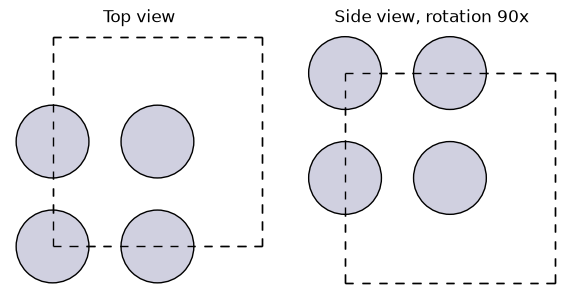

In [4]:
import matplotlib.pyplot as plt
from ase.visualize.plot import plot_atoms

fig, axes = plt.subplots(1, 2, figsize=(6, 3))

plot_atoms(pt_bulk, axes[0], radii=0.5)
axes[0].set_title("Top view", fontsize=12)

plot_atoms(pt_bulk, axes[1], radii=0.5, rotation="90x")
axes[1].set_title("Side view, rotation 90x", fontsize=12)

fig.tight_layout()
plt.show()

## 4. The command line tools

- ASE also installs a command called `ase`, which does small jobs without writing any Python
    - Type these in a terminal, in this module folder, with `(mlip-mace)` shown in the prompt
    - `ase info` reports the versions of ASE and of the packages it uses
    - `ase info --files work/Pt_bulk.cif work/Pt_bulk.xyz work/Pt_bulk.traj work/POSCAR_Pt_bulk` reports which format ASE thinks each file is
    - `ase convert -v -f work/Pt_bulk.cif work/Pt_bulk_from_cif.xyz` rewrites a file in another format
    - `ase build -x fcc -a 3.92 --cubic Pt work/Pt_ase.cif` builds a structure from scratch and writes it
    - `ase gui work/Pt_bulk.cif` is the viewer of the section on looking at a structure, the same command family
- The flags used above
    - `-v` makes `ase convert` report the file it wrote; without it a conversion that worked prints nothing at all
    - `-f` allows `ase convert` to overwrite the output file; without it the command stops when that file already exists, which protects data you meant to keep
    - `-x fcc` is the crystal structure, `-a 3.92` the lattice constant in Å, and `--cubic` asks for the cubic cell rather than the smallest one
- The cell below runs the same commands from Python, so that the notebook reproduces them
    - `subprocess` comes with Python and starts another program from inside Python
    - `subprocess.run(cmd, capture_output=True, text=True)` runs the command and keeps its output as text instead of printing it
    - `result.stdout` is the normal output, `result.stderr` the error output, and `result.returncode` is 0 when the command worked
    - `sys` also comes with Python, and `sys.executable` is the Python running this notebook; the `ase` command sitting next to it is the one belonging to this environment
    - `" ".join(words)` glues a list of words into one line with spaces between them, which is how the command is printed
    - When a command fails, the cell prints the last of its error text and stops with `raise SystemExit(...)`, so that no later cell works on a missing file
    - The printed command line says `ase`, which is what you type in the terminal
- `ase info` prints one line per package: the name with its version first, then the folder it is installed in
    - The cell prints the first part of each line only, because that folder is different on every computer
- `text.splitlines()` cuts a block of text into a list of lines, and `line.split()[0]` keeps the first word of a line

In [5]:
import subprocess
import sys

ASE = Path(sys.executable).parent / "ase"     # the ase command of this environment


def run(cmd):
    """Run one ase command and give its normal output back as text."""
    print("Command")
    print(" ".join(["ase"] + cmd[1:]))
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stderr.strip()[-500:])
        raise SystemExit("the ase command failed")
    return result.stdout


info = run([str(ASE), "info"])
print("Package and version, six lines")
for line in info.splitlines()[1:7]:
    print(line.split()[0])

print()
file_report = run([str(ASE), "info", "--files",
                   "work/Pt_bulk.cif", "work/Pt_bulk.xyz",
                   "work/Pt_bulk.traj", "work/POSCAR_Pt_bulk"])
print("Format ASE reads out of each file")
print(file_report.strip())

print()
converted = run([str(ASE), "convert", "-v", "-f",
                 "work/Pt_bulk.cif", "work/Pt_bulk_from_cif.xyz"])
print("File written by ase convert")
print(converted.strip())

print()
run([str(ASE), "build", "-x", "fcc", "-a", "3.92", "--cubic",
     "Pt", "work/Pt_ase.cif"])
built = read(WORK / "Pt_ase.cif")
print("Atoms in the file ase build wrote")
print(len(built))
print("Cell vector lengths of that file (Å)")
print(np.round(built.cell.lengths(), 3))

Command
ase info


Package and version, six lines
python-3.11.10
ase-3.29.0
numpy-2.4.6
scipy-1.17.1
matplotlib-3.11.2
spglib-2.7.0

Command
ase info --files work/Pt_bulk.cif work/Pt_bulk.xyz work/Pt_bulk.traj work/POSCAR_Pt_bulk


Format ASE reads out of each file
work/Pt_bulk.cif:    CIF-file (cif)
work/Pt_bulk.xyz:    Extended XYZ file (extxyz)
work/Pt_bulk.traj:   ASE trajectory (traj)
work/POSCAR_Pt_bulk: VASP POSCAR/CONTCAR (vasp)

Command
ase convert -v -f work/Pt_bulk.cif work/Pt_bulk_from_cif.xyz


File written by ase convert
work/Pt_bulk.cif -> work/Pt_bulk_from_cif.xyz

Command
ase build -x fcc -a 3.92 --cubic Pt work/Pt_ase.cif


Atoms in the file ase build wrote
4
Cell vector lengths of that file (Å)
[3.92 3.92 3.92]


## 5. Move atoms

- Moving atoms is how every adsorbate is placed and every starting guess is built
- `atoms.copy()` makes a separate structure
    - Without it, the change would also alter the structure read by the section on reading and writing files, because both names would point at the same object
    - Copy before you change, every time
- Three ways to move, from one atom to the whole structure
    - `atoms.positions[i] += [0, 0, 0.5]` adds 0.5 Å to the z of atom `i` only
    - `atoms.translate([0, 0, 1.0])` adds the same shift to every atom, so the structure moves as one piece
    - `atoms.center(vacuum=5.0, axis=2)` puts the atoms in the middle of the cell along z and leaves 5 Å of empty space above and below them
- `center(vacuum=..., axis=2)` is how a surface gets its vacuum from module 04 on
    - A slab repeats endlessly in z as well, so without empty space the slab would touch its own next copy
    - It changes the cell: the new length along z is the height of the atoms plus twice the vacuum
    - Here it is applied to a bulk crystal only to show the effect; the result is a thin slab with empty space above and below it, and no longer the crystal
- Reading positions out of the array, as in module 01
    - `positions[i, 2]` is the z of atom `i`, and `positions[:, 2]` is the z column of every atom
    - `.max()` and `.min()` are the largest and smallest value of what they are asked about
    - `round(float(value), 3)` turns one number of the array into a plain number and rounds it for printing

In [6]:
moved = pt_bulk.copy()

print("z of atom 1, as read from the file (Å)")
print(round(float(moved.positions[1, 2]), 3))

moved.positions[1] += [0.0, 0.0, 0.5]
print("z of atom 1 after adding 0.5 to it (Å)")
print(round(float(moved.positions[1, 2]), 3))

moved.translate([0.0, 0.0, 1.0])
print("z of atom 1 after moving the whole structure by 1.0 (Å)")
print(round(float(moved.positions[1, 2]), 3))
print("z of atom 0 after the same move, which had not been touched before (Å)")
print(round(float(moved.positions[0, 2]), 3))

spaced = moved.copy()
spaced.center(vacuum=5.0, axis=2)

print()
print("Cell length along z before centering (Å)")
print(round(float(moved.cell.lengths()[2]), 3))
print("Cell length along z after centering with 5 Å of vacuum (Å)")
print(round(float(spaced.cell.lengths()[2]), 3))
print("Lowest z after centering (Å)")
print(round(float(spaced.positions[:, 2].min()), 3))
print("Highest z after centering (Å)")
print(round(float(spaced.positions[:, 2].max()), 3))

z of atom 1, as read from the file (Å)
1.96
z of atom 1 after adding 0.5 to it (Å)
2.46
z of atom 1 after moving the whole structure by 1.0 (Å)
3.46
z of atom 0 after the same move, which had not been touched before (Å)
1.0

Cell length along z before centering (Å)
3.92
Cell length along z after centering with 5 Å of vacuum (Å)
12.46
Lowest z after centering (Å)
5.0
Highest z after centering (Å)
7.46


## 6. Rotate a fragment

- A fragment is a group of atoms treated as one piece, such as the OH or OOH group that sits on a surface from module 07 on
- Turning a fragment is how a different starting orientation is tried when a relaxation ends in a poor geometry
- `from ase.build import molecule` brings in ASE's library of small molecules
    - `molecule("H2O")` gives water with its known geometry, and here the order is O, H, H, so the oxygen is atom 0
    - The order of `molecule("H2O")` is not the order of `Atoms("H2O", ...)` in the section on the Atoms object; always check the symbols before using an index
- `atoms.rotate(90, "z", center=atoms[0].position)` turns the whole structure by 90° about the z axis
    - `center=` is the point that stays where it is; here the oxygen, so only the hydrogens move
    - Leaving `center=` out turns the structure about the origin of the coordinates, which also moves it away from where it was
    - `atoms.euler_rotate(phi=..., theta=..., psi=...)` is the general form, three angles about three axes, used when one angle is not enough
- A rotation moves atoms but changes no distance inside the fragment, which the printed O to H distance confirms
    - `atoms.get_distance(i, j)` is the distance between two atoms in Å; the section on distances and neighbours comes back to it for periodic structures
- To turn one fragment inside a larger structure, take the fragment out with `atoms[[i, j, k]]`, rotate that small object, and write its positions back into the big one
- `positions[1:]` is every row of the array except the first, so here the two hydrogens
- A number printed as `-0.` is zero: the minus sign survives the rounding of a very small negative number

In [7]:
from ase.build import molecule

water_mol = molecule("H2O")
distance_before = water_mol.get_distance(0, 1)

print("Chemical symbols, in the order ASE stores them")
print(water_mol.get_chemical_symbols())
print("Position of atom 0, the oxygen (Å)")
print(np.round(water_mol[0].position, 3))
print("Positions of the two H atoms before the rotation (Å)")
print(np.round(water_mol.positions[1:], 3))

water_mol.rotate(90, "z", center=water_mol[0].position)

print()
print("Positions of the two H atoms after turning 90° about z through the oxygen (Å)")
print(np.round(water_mol.positions[1:], 3))
print("Position of atom 0 after the rotation (Å)")
print(np.round(water_mol[0].position, 3))

print()
print("O to H distance before the rotation (Å)")
print(round(float(distance_before), 3))
print("O to H distance after the rotation (Å)")
print(round(float(water_mol.get_distance(0, 1)), 3))

Chemical symbols, in the order ASE stores them
['O', 'H', 'H']
Position of atom 0, the oxygen (Å)
[0.    0.    0.119]
Positions of the two H atoms before the rotation (Å)
[[ 0.     0.763 -0.477]
 [ 0.    -0.763 -0.477]]

Positions of the two H atoms after turning 90° about z through the oxygen (Å)
[[-0.763  0.    -0.477]
 [ 0.763 -0.    -0.477]]
Position of atom 0 after the rotation (Å)
[0.    0.    0.119]

O to H distance before the rotation (Å)
0.969
O to H distance after the rotation (Å)
0.969


## 7. Supercells

- A supercell is the same crystal described with a bigger box: the cell is repeated a whole number of times in one or more directions
    - The material is unchanged; only the description grows, and so does the cost of the calculation
- Two spellings of the same operation, both giving a new structure
    - `atoms.repeat((2, 2, 2))` repeats twice along each of the three cell vectors, so eight copies and eight times the atoms
    - `atoms * (2, 2, 1)` repeats twice in the two in-plane directions and leaves the third alone, so four copies
    - In-plane means along the two cell vectors of the surface; the third one is the direction the surface looks along
- Why the in-plane size of a surface cell matters
    - An adsorbate on a surface sits in a cell that repeats, so it has a copy of itself in every neighbouring cell
    - In a small cell those copies are close enough to interact, and the calculated adsorption energy then describes a dense layer instead of one isolated adsorbate
    - Making the cell bigger in plane pushes the copies apart, at the price of more atoms and a longer calculation
- The group's decision, canon `S6`: the shortest in-plane lattice vector of a surface or adsorption cell is about 7.5 Å
    - This is a project decision recorded in the group's `CANON.md`, not a default of any tool; your supervisor sets it for your project
    - The cubic Pt cell is 3.92 Å, well under that minimum; repeated `(2, 2, 1)` it becomes 7.84 Å in plane, which clears it
    - Module 04 builds the Pt(111) slabs of this course, and the same rule decides their size
- `cell.lengths()[:2]` is the length of the first two cell vectors, and `min(...)` the shorter of the two

In [8]:
cell_222 = pt_bulk.repeat((2, 2, 2))
cell_221 = pt_bulk * (2, 2, 1)

print("Atoms in the original cell")
print(len(pt_bulk))
print("Cell vector lengths of the original cell (Å)")
print(np.round(pt_bulk.cell.lengths(), 3))

print()
print("Atoms after repeat((2, 2, 2))")
print(len(cell_222))
print("Cell vector lengths after repeat((2, 2, 2)) (Å)")
print(np.round(cell_222.cell.lengths(), 3))

print()
print("Atoms after multiplying by (2, 2, 1)")
print(len(cell_221))
print("Cell vector lengths after multiplying by (2, 2, 1) (Å)")
print(np.round(cell_221.cell.lengths(), 3))

print()
print("Shortest in-plane vector of the original cell (Å)")
print(round(float(min(pt_bulk.cell.lengths()[:2])), 3))
print("Shortest in-plane vector after multiplying by (2, 2, 1) (Å)")
print(round(float(min(cell_221.cell.lengths()[:2])), 3))

Atoms in the original cell
4
Cell vector lengths of the original cell (Å)
[3.92 3.92 3.92]

Atoms after repeat((2, 2, 2))
32
Cell vector lengths after repeat((2, 2, 2)) (Å)
[7.84 7.84 7.84]

Atoms after multiplying by (2, 2, 1)
16
Cell vector lengths after multiplying by (2, 2, 1) (Å)
[7.84 7.84 3.92]

Shortest in-plane vector of the original cell (Å)
3.92
Shortest in-plane vector after multiplying by (2, 2, 1) (Å)
7.84


## 8. Fix atoms

- A constraint is a rule attached to a structure that says which atoms are not allowed to move
    - The rule travels with the structure: it is written into the file and honoured by the optimizers of module 06 on
    - From module 04 on, the bottom layers of a slab are fixed this way, so that they keep the geometry of the bulk material while the surface relaxes
    - How many layers are fixed is decided by your supervisor for the project, never taken from a tool default
- `from ase.constraints import FixAtoms` brings in the only constraint this course uses
    - `FixAtoms(indices=[0, 1])` fixes the atoms with those indices, in all three directions
    - `atoms.set_constraint(...)` attaches it, replacing whatever was attached before
    - `atoms.constraints` lists what is attached, and `atoms.constraints[0].get_indices()` gives the fixed indices back
- What this looks like inside a `POSCAR` file
    - A line reading `Selective dynamics` appears above the line `Direct`, which is how VASP is told that flags follow
    - Every atom line then ends with three flags: `F F F` for an atom fixed in all three directions, `T T T` for a free one
    - The flags are in the order the atoms are written in the file
- `sort=True` groups the atoms by species before writing, so the index of an atom in the file can differ from its index in the `Atoms` object
    - Here, with 4 atoms of one species, the order happens to stay the same
    - Module 04 shows that on a larger structure the same call reorders atoms of one species, so always read the flags back from the file
    - With two or more species, the order can change as well, so read the flags from the file rather than trusting the original indices
- `path.read_text()` reads a whole text file into one piece of text, and `[:600]` keeps its first 600 characters

In [9]:
from ase.constraints import FixAtoms

fixed = pt_bulk.copy()
fixed.set_constraint(FixAtoms(indices=[0, 1]))

print("Constraints attached to the structure")
print(fixed.constraints)
print("Indices of the fixed atoms")
print(fixed.constraints[0].get_indices())
print("Number of atoms free to move")
print(len(fixed) - len(fixed.constraints[0].get_indices()))

poscar = WORK / "POSCAR_Pt_fixed"
write(poscar, fixed, format="vasp", direct=True, sort=True)

print()
print("First 600 characters of the POSCAR file")
print(poscar.read_text()[:600])

Constraints attached to the structure
[FixAtoms(indices=[0, 1])]
Indices of the fixed atoms
[0 1]
Number of atoms free to move
2

First 600 characters of the POSCAR file
Pt
 1.0000000000000000
     3.9199999999999999    0.0000000000000000    0.0000000000000000
     0.0000000000000000    3.9199999999999999    0.0000000000000000
     0.0000000000000000    0.0000000000000000    3.9199999999999999
 Pt 
   4
Selective dynamics
Direct
  0.0000000000000000  0.0000000000000000  0.0000000000000000   F   F   F
  0.0000000000000000  0.5000000000000000  0.5000000000000000   F   F   F
  0.5000000000000000  0.0000000000000000  0.5000000000000000   T   T   T
  0.5000000000000000  0.5000000000000000  0.0000000000000000   T   T   T



## 9. Distances and neighbours

- A distance between two atoms is the first check on any structure: a bond that is far too short or too long means the structure is wrong
- In a periodic structure the distance between two atoms is not unique, because each atom has a copy in every neighbouring cell
    - The minimum image convention takes the shortest of all those distances, which is the one that means something physically
    - `mic=True` switches it on, and it is the right choice for any structure with `pbc` set to `True`
    - For a molecule in vacuum it makes no difference, because there are no copies
- `atoms.get_distance(i, j, mic=True)` is the distance between two atoms in Å
- `atoms.get_all_distances(mic=True)` gives the whole table at once
    - A NumPy array of shape (N, N): row `i`, column `j` holds the distance from atom `i` to atom `j`
    - The diagonal is zero, because it is the distance from an atom to itself
    - `d[d > 0]` keeps only the values above zero, which drops that diagonal, and `.min()` is the smallest of what is left
    - The table has N times N entries, so it is fine for a cell of this size and slow for thousands of atoms; `ase.neighborlist` is the tool for those
- The check on the Pt crystal
    - In a face-centred cubic crystal with lattice constant `a`, the nearest neighbour distance is `a / sqrt(2)`
    - With `a = 3.92 Å` that is 2.772 Å, and the cell prints both numbers so that they can be compared
    - `np.sqrt(2)` is the square root of two
- The demonstration of the minimum image convention
    - Atom 1 is moved by exactly one cell vector, 3.92 Å along y, which gives the same crystal back
    - Without `mic` the distance grows, because the code measures to the atom where it was written
    - With `mic` it stays at the nearest neighbour distance, because the nearest copy of atom 1 is used

In [10]:
print("Distance from atom 0 to atom 1, minimum image (Å)")
print(round(float(pt_bulk.get_distance(0, 1, mic=True)), 3))
print("Nearest neighbour distance expected for face-centred cubic Pt, 3.92 / sqrt(2) (Å)")
print(round(float(3.92 / np.sqrt(2)), 3))

distances = pt_bulk.get_all_distances(mic=True)

print()
print("All distances between the four atoms, minimum image (Å)")
print(np.round(distances, 3))
print("Shortest distance between two different atoms (Å)")
print(round(float(distances[distances > 0].min()), 3))

shifted = pt_bulk.copy()
shifted.positions[1] += [0.0, 3.92, 0.0]

print()
print("Position of atom 1 after moving it by one cell vector (Å)")
print(np.round(shifted.positions[1], 3))
print("Distance from atom 0 to atom 1 without the minimum image (Å)")
print(round(float(shifted.get_distance(0, 1, mic=False)), 3))
print("Distance from atom 0 to atom 1 with the minimum image (Å)")
print(round(float(shifted.get_distance(0, 1, mic=True)), 3))

Distance from atom 0 to atom 1, minimum image (Å)
2.772
Nearest neighbour distance expected for face-centred cubic Pt, 3.92 / sqrt(2) (Å)
2.772

All distances between the four atoms, minimum image (Å)
[[0.    2.772 2.772 2.772]
 [2.772 0.    2.772 2.772]
 [2.772 2.772 0.    2.772]
 [2.772 2.772 2.772 0.   ]]
Shortest distance between two different atoms (Å)
2.772

Position of atom 1 after moving it by one cell vector (Å)
[0.   5.88 1.96]
Distance from atom 0 to atom 1 without the minimum image (Å)
6.198
Distance from atom 0 to atom 1 with the minimum image (Å)
2.772


## Check yourself

1. The section on moving atoms begins with `moved = pt_bulk.copy()`. What would go wrong further down the
   notebook if the `.copy()` were left out?
2. A Pt(111) surface cell has in-plane vectors of 5.5 Å. Your supervisor asks for a cell that follows canon
   `S6`. What do you do to the cell, and what does that do to the number of atoms?
3. `atoms.get_distance(4, 17)` gives 9.8 Å for two atoms that look like neighbours in `ase gui`. What is the
   most likely reason, and which argument do you add?

<details>
<summary>Answers</summary>

- `moved` and `pt_bulk` would be two names for the same object, so moving atom 1 and translating the
  structure would also change `pt_bulk`; the supercell, fix-atoms and distance sections all start from
  `pt_bulk`, so the supercells and every printed distance would then describe the moved structure instead of
  the crystal
- Repeat the cell in plane, `atoms * (2, 2, 1)`, which gives 11.0 Å and four times the atoms; canon `S6` asks
  for about 7.5 Å as the shortest in-plane vector, and 5.5 Å is below it
- The two atoms are neighbours across the cell boundary, so the distance was measured to the far copy;
  add `mic=True`, which takes the shortest distance among all periodic copies

</details>